## 02. Neural Network classification with PyTorch

Classification is the problem of predicting whether something is one thing or another (there can be multiple things as the options).

## Import Libraries 

In [37]:
import torch 
import torch.nn as nn 
import torch.optim as optim 
print(torch.__version__)

from sklearn.model_selection import train_test_split

2.14.1+cu130


In [38]:
from sklearn.datasets import make_circles

X, y = make_circles(
    n_samples=1000,
    shuffle=True,
    noise=0.04,
    random_state=42
)

In [39]:
len(X), len(y)

(1000, 1000)

In [40]:
print(f"First Five samples of X:\n  {X[:5]}")
print(f"First Five samples of y:\n  {y[:5]}")

First Five samples of X:
  [[ 0.74822656  0.23908325]
 [-0.74509559  0.16097526]
 [-0.82262532  0.19762051]
 [-0.41143316  0.68255648]
 [ 0.44390494 -0.89582949]]
First Five samples of y:
  [1 1 1 1 0]


In [41]:
# Make DataFrame of circle data 

import pandas as pd 
circles = pd.DataFrame({"X1":X[:, 0],
                       "X2":X[:, 1],
                       "Label": y })

In [42]:
circles.head()

,X1,X2,Label
0,0.748227,0.239083,1
1,-0.745096,0.160975,1
2,-0.822625,0.197621,1
3,-0.411433,0.682556,1
4,0.443905,-0.895829,0


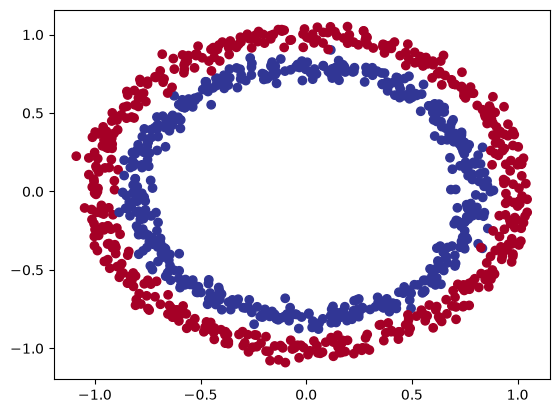

In [43]:
# Visualize

import matplotlib.pyplot as plt

plt.scatter(x=X[:,0],
            y=X[:, 1],
            c=y,
            cmap=plt.cm.RdYlBu)
plt.show()

 # 1.1 Check input and outputs shapes 

In [44]:
X.shape, y.shape

((1000, 2), (1000,))

In [45]:
# view the first example of the features and labels 

x_sample = X[0]

y_sample = y[0]

print(f"Values for one sample of X: {x_sample} and the same for y: {y_sample}")
print(f"Shapes for one sample of X: {x_sample.shape} and the same for y: {y_sample.shape}")

Values for one sample of X: [0.74822656 0.23908325] and the same for y: 1
Shapes for one sample of X: (2,) and the same for y: ()


### 1.2 Trun data into tensors and create train and test splits 

In [46]:
# Check the data type of the x 
type(X)

numpy.ndarray

In [47]:
# Convert data into the tensors 

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

In [48]:
X.type(), y.type()

('torch.FloatTensor', 'torch.FloatTensor')

In [49]:
X[:5], y[:5]

(tensor([[ 0.7482,  0.2391],
         [-0.7451,  0.1610],
         [-0.8226,  0.1976],
         [-0.4114,  0.6826],
         [ 0.4439, -0.8958]]),
 tensor([1., 1., 1., 1., 0.]))

### Split data into training and test sets

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2, # 20% is testing data and remaning is Training data 
                                                    random_state=42,
                                                    stratify=y)

In [51]:
len(X_train), len(X_test) , len(y_train), len(y_test)

(800, 200, 800, 200)

### Setup Devices

In [52]:
if torch.cuda.is_available():
    device = "cuda"

else: 
    device = "cpu"


print("Device", device)

Device cuda


## 2. Building a model 

In [53]:
# 1. Construct a model that subclasses nn.module


class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(in_features=2, out_features=5) #Upscale to 5
        self.layer_2 = nn.Linear(in_features=5, out_features=1)


    def forward(self, x):
        return self.layer_2(self.layer_1(x)) # x -> layer_1 -> layer_2


model_0 = CircleModelV0().to(device)

In [54]:
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [55]:
next(model_0.parameters()).device

device(type='cuda', index=0)

## Visualizing the Model

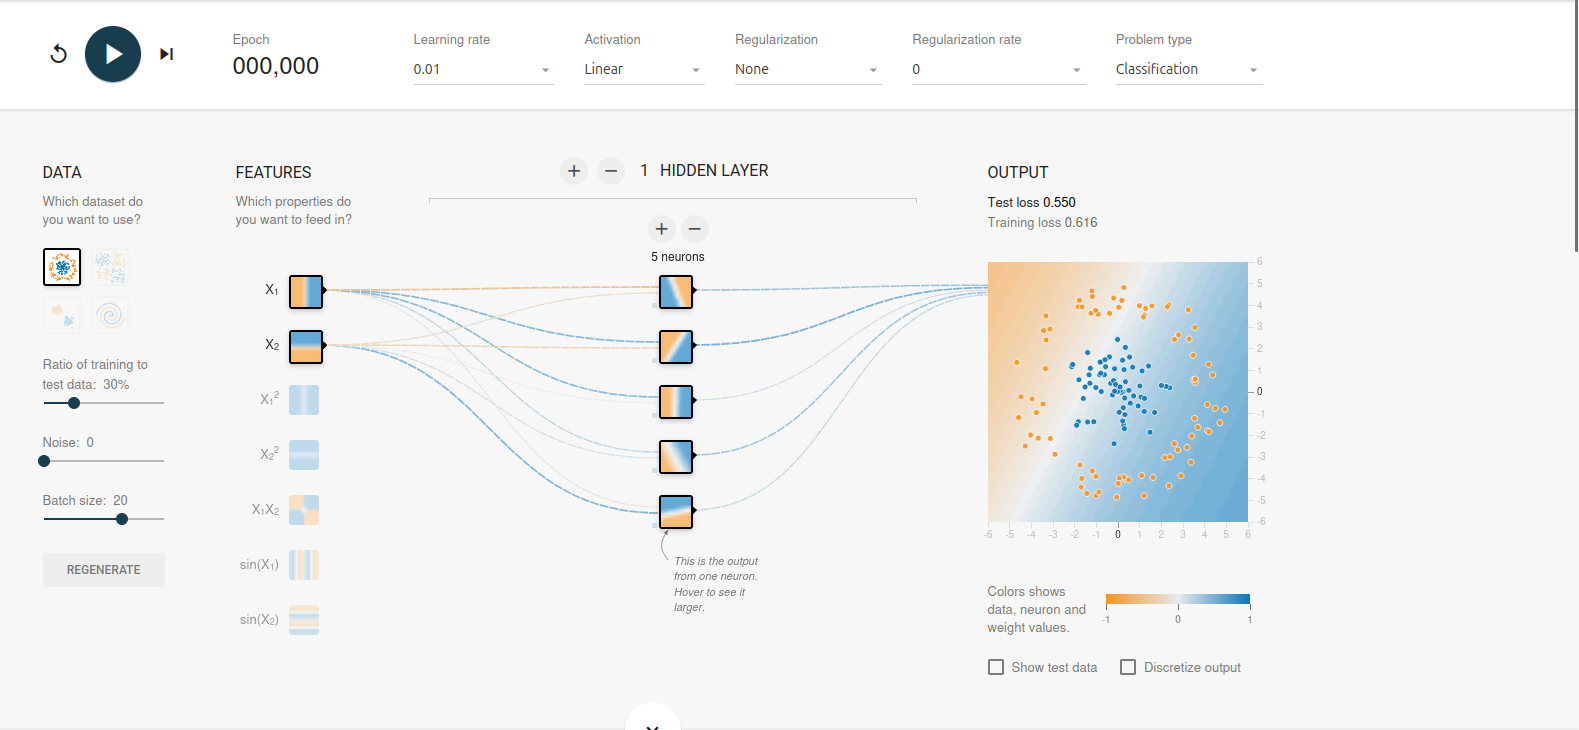

In [56]:
## Building Model Using nn.Sequential()

model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.ReLU(),

    nn.Linear(in_features=5, out_features=1)
).to(device=device)

model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): ReLU()
  (2): Linear(in_features=5, out_features=1, bias=True)
)

In [57]:
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.0829, -0.2872],
                      [ 0.4691, -0.5582],
                      [-0.3260, -0.1997],
                      [-0.4252,  0.0667],
                      [-0.6984,  0.6386]], device='cuda:0')),
             ('0.bias',
              tensor([-0.6007,  0.5459,  0.1177, -0.2296,  0.4370], device='cuda:0')),
             ('2.weight',
              tensor([[ 0.0697,  0.3613,  0.0489, -0.1410,  0.1202]], device='cuda:0')),
             ('2.bias', tensor([-0.1213], device='cuda:0'))])

In [58]:
# Make Predictions
with torch.inference_mode():

    untrained_preds = model_0(X_test.to(device))

print(f"Length of predictions: {len(untrained_preds)}, shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(y_test)}, Shape: {y_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 test labels:\n{y_test[:10]}")

Length of predictions: 200, shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200])

First 10 predictions:
tensor([[0.1463],
        [0.2375],
        [0.2711],
        [0.1355],
        [0.0217],
        [0.1111],
        [0.2447],
        [0.0355],
        [0.0217],
        [0.3537]], device='cuda:0')

First 10 test labels:
tensor([1., 0., 0., 0., 1., 1., 1., 1., 0., 0.])


In [59]:
loss_fn =  nn.BCEWithLogitsLoss()  # Builtin  Sigmoid Activation  Function
optimizer = optim.SGD(params=model_0.parameters(), 
                      lr=0.01)


# Calculate accuracy 
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct/len(y_pred)) * 100

    return acc


## Train model 

Our model outputs are going to be raw **logits** 

We can convert these **logits** into prediction probabilities by passing them to some kind of activation function.
Example:
1. sigmoid for binary classification 
2. softmax  for multiclass classification 

Then We can convert our model's prediction probabilities to prediction labels by either rounding them or taking the argmax().


In [60]:
# View the first 5 outputs of the forward pass on the  test data

model_0.eval()

with torch.inference_mode():
    y_logits = model_0(X_test.to(device)) [:5]

y_logits 

tensor([[0.1463],
        [0.2375],
        [0.2711],
        [0.1355],
        [0.0217]], device='cuda:0')

In [61]:
y_test[:5]

tensor([1., 0., 0., 0., 1.])

In [62]:
# Use the sigmoid activation function on our model logits to turn them into prediction probabilities 

y_pred_probs = torch.sigmoid(y_logits)

y_pred_probs

tensor([[0.5365],
        [0.5591],
        [0.5674],
        [0.5338],
        [0.5054]], device='cuda:0')

### For our prediction probability values, we need to perform a range-style rounding on them:

* `y_pred_probs` >= 0.5, `y=1` (CLASS 1)
* `y_pred_probs` < 0.5, `y=0` (CLASS 0)

In [63]:
# Find the predicted labels 

y_preds = torch.round(y_pred_probs)

# In full 

y_pred_labels = torch.round(torch.sigmoid(model_0(X_test.to(device)))) [:5]

# Check for equality 
print(torch.eq(y_preds.squeeze(), y_pred_labels.squeeze()))

# Get rid  of Extra Dimension 

y_preds.squeeze()

tensor([True, True, True, True, True], device='cuda:0')


tensor([1., 1., 1., 1., 1.], device='cuda:0')

### Building the Training and Testing loops

In [64]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Set the number of epochs 

epochs = 1000

# Put data to target device 

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    model_0.train()

    # Forward pass 

    y_logits = model_0(X_train).squeeze()

    y_pred =  torch.round(torch.sigmoid(y_logits))

    # calculate the accuracy 


    loss = loss_fn(y_logits, y_train)

    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()


    model_0.eval()

    with torch.inference_mode():
        X_test_logits = model_0(X_test).squeeze()

        x_preds = torch.round(torch.sigmoid(X_test_logits))

        test_loss = loss_fn(X_test_logits, y_test)

        test_acc = accuracy_fn(y_true=y_test,
                                    y_pred=x_preds)

        



    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.70009, Accuracy: 50.00% | Test loss: 0.70296, Test acc: 50.00%
Epoch: 10 | Loss: 0.69973, Accuracy: 50.00% | Test loss: 0.70259, Test acc: 51.00%
Epoch: 20 | Loss: 0.69940, Accuracy: 51.00% | Test loss: 0.70224, Test acc: 52.50%
Epoch: 30 | Loss: 0.69910, Accuracy: 50.88% | Test loss: 0.70192, Test acc: 53.00%
Epoch: 40 | Loss: 0.69882, Accuracy: 49.38% | Test loss: 0.70161, Test acc: 51.50%
Epoch: 50 | Loss: 0.69855, Accuracy: 48.62% | Test loss: 0.70133, Test acc: 47.00%
Epoch: 60 | Loss: 0.69831, Accuracy: 51.62% | Test loss: 0.70107, Test acc: 48.00%
Epoch: 70 | Loss: 0.69808, Accuracy: 53.50% | Test loss: 0.70082, Test acc: 53.00%
Epoch: 80 | Loss: 0.69786, Accuracy: 53.50% | Test loss: 0.70059, Test acc: 52.00%
Epoch: 90 | Loss: 0.69766, Accuracy: 53.25% | Test loss: 0.70038, Test acc: 52.00%
Epoch: 100 | Loss: 0.69747, Accuracy: 53.25% | Test loss: 0.70018, Test acc: 52.50%
Epoch: 110 | Loss: 0.69730, Accuracy: 52.62% | Test loss: 0.69999, Test acc: 53.50%
Epo

In [65]:
import requests

from pathlib import Path

# Download helper functions from learn PyTorch repo ( if it's not already downloaded)

if Path("helper_functions.py").is_file():
    print("hepler_functions.py already exists, skipping download")

else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

hepler_functions.py already exists, skipping download


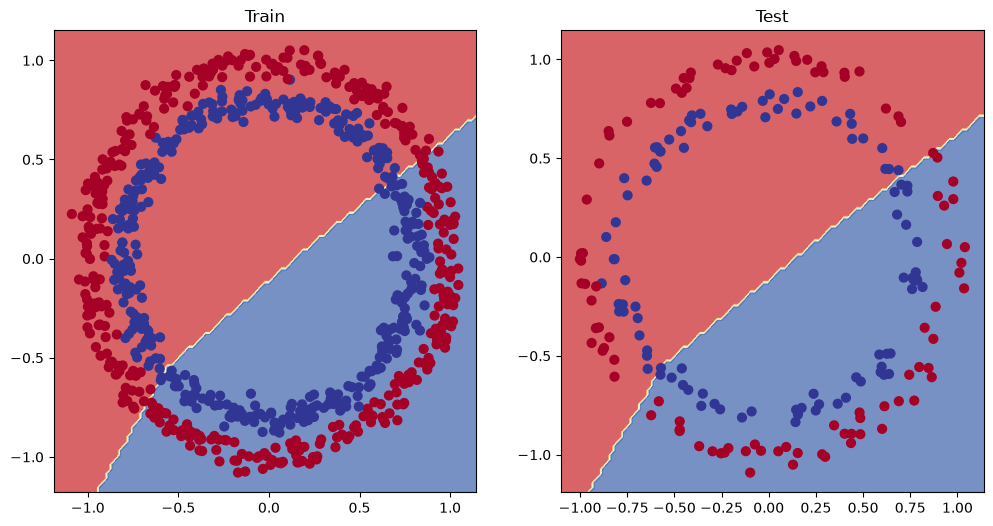

In [66]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

## Improving a model (from a model perspective)

* Add more layers -give the model more chances to learn abouts the patterns 
* Add more hidden units 
* Fit for longer 
* Changing the activation functions 
* change the learning rate 
* change the loss function 

This options are all from a model's perspective because they deal directly with the model, rather than the data.
And because these ioptions are all values we (as machine learning engineers and data scientists) can change, they  referred as the **hyperparameters.**

In [67]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.model_1 = nn.Sequential(
            nn.Linear(in_features=2, out_features=10),
            nn.ReLU(),

            nn.Linear(10, 10),
            nn.ReLU(),

            nn.Linear(10, 1)

        )

    def forward(self, x):
        return self.model_1(x)
    

In [68]:
model_1 = CircleModelV1()
loss_function = nn.BCEWithLogitsLoss()
optimizer =  optim.SGD(params = model_1.parameters(), 
                       lr= 0.1)

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 1000

# Put data to target device 

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    model_0.train()

    # Forward pass 

    y_logits = model_0(X_train).squeeze()

    y_pred =  torch.round(torch.sigmoid(y_logits))

    # calculate the accuracy 


    loss = loss_fn(y_logits, y_train)

    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()


    model_0.eval()

    with torch.inference_mode():
        X_test_logits = model_0(X_test).squeeze()

        x_preds = torch.round(torch.sigmoid(X_test_logits))

        test_loss = loss_fn(X_test_logits, y_test)

        test_acc = accuracy_fn(y_true=y_test,
                                    y_pred=x_preds)

        



    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


SyntaxError: invalid syntax (4066089123.py, line 4)